In [2]:

import torch
import torch.nn as nn

#permet de charger les données (batches)
from torch.utils.data import DataLoader
#transforme une image en tenseur
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

import matplotlib.pyplot as plt

import numpy as np

# Vérifier si un GPU compatible CUDA est disponible

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Appareil utilisé :", device)

if torch.cuda.is_available():
    print("Nom du GPU :", torch.cuda.get_device_name(0))


Appareil utilisé : cuda
Nom du GPU : Tesla T4


In [3]:

# Transformer les images en tenseurs PyTorch
transform = ToTensor()

# Charger les données d'entraînement
# train=True signifie qu'on récupère la partie destinée à l'apprentissage
train_set = MNIST(
    root="./datasets",
    train=True,
    download=True,
    transform=transform
)

# Charger les données de test
# train=False signifie qu'on récupère la partie destinée à l'évaluation finale
test_set = MNIST(
    root="./datasets",
    train=False,
    download=True,
    transform=transform
)

# Afficher le nombre d'images dans chaque partie
print("Nombre d'images d'entraînement :", len(train_set))
print("Nombre d'images de test :", len(test_set))



100%|██████████| 9.91M/9.91M [00:00<00:00, 18.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 485kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.36MB/s]

Nombre d'images d'entraînement : 60000
Nombre d'images de test : 10000


In [4]:

# Nombre d'images traitées ensemble pendant une étape d'entraînement
batch_size = 128

# Charger les images d'entraînement par lots de 128
# shuffle=True mélange l'ordre des images à chaque époque
train_loader = DataLoader(
    train_set,
    batch_size=batch_size,
    shuffle=True
)

# Charger les images de test par lots de 128
# shuffle=False conserve l'ordre des données de test
test_loader = DataLoader(
    test_set,
    batch_size=batch_size,
    shuffle=False
)

print("Nombre de batches d'entraînement :", len(train_loader))
print("Nombre de batches de test :", len(test_loader))


Nombre de batches d'entraînement : 469
Nombre de batches de test : 79


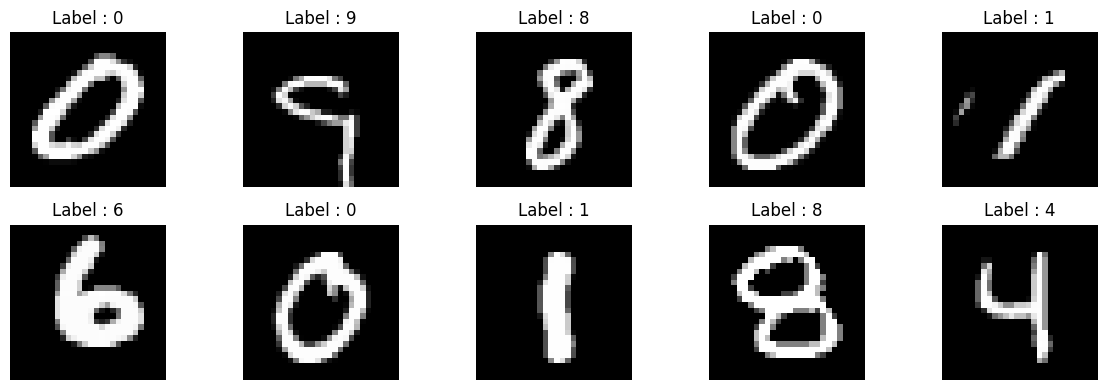

Forme des images : torch.Size([128, 1, 28, 28])
Forme des étiquettes : torch.Size([128])


In [5]:

# Récupérer un premier batch d'images et leurs étiquettes
images, labels = next(iter(train_loader))

# Afficher les 10 premières images du batch
plt.figure(figsize=(12, 4))

for i in range(10):
    # Créer un emplacement pour chaque image
    plt.subplot(2, 5, i + 1)

    # Enlever la dimension du canal pour afficher l'image en 2D
    plt.imshow(images[i].squeeze(), cmap="gray")

    # Afficher le vrai chiffre correspondant à l'image
    plt.title(f"Label : {labels[i].item()}")

    # Cacher les axes pour rendre l'affichage plus clair
    plt.axis("off")

plt.tight_layout()
plt.show()

# Afficher la forme du batch
print("Forme des images :", images.shape)
print("Forme des étiquettes :", labels.shape)


In [6]:

# Définir notre réseau de neurones convolutif
class CNN(nn.Module):

    def __init__(self):
        # Initialiser la classe parente PyTorch
        super(CNN, self).__init__()

        # Première couche convolutionnelle :
        # 1 canal en entrée, 16 cartes de caractéristiques en sortie
        # kernel_size=3 : chaque filtre regarde une zone de 3x3 pixels
        # padding=1 : conserve la hauteur et la largeur de l'image
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        # Fonction d'activation : conserve les valeurs positives
        # et remplace les valeurs négatives par zéro
        self.relu1 = nn.ReLU()

        # Réduire la hauteur et la largeur de moitié
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Deuxième convolution :
        # elle reçoit les 16 cartes de caractéristiques précédentes
        # et en produit 32 nouvelles
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Deuxième fonction d'activation
        self.relu2 = nn.ReLU()

        # Deuxième réduction spatiale
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Transformer les caractéristiques en 128 valeurs
        # 32 canaux * 7 pixels * 7 pixels = 1568 entrées
        self.fc1 = nn.Linear(32 * 7 * 7, 128)

        # Fonction d'activation après la première couche dense
        self.relu3 = nn.ReLU()

        # Produire un score pour chacun des 10 chiffres : 0 à 9
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # Étape 1 : détecter des caractéristiques dans l'image
        x = self.conv1(x)

        # Étape 2 : appliquer l'activation ReLU
        x = self.relu1(x)

        # Étape 3 : réduire les dimensions spatiales
        x = self.pool1(x)

        # Étape 4 : extraire des caractéristiques supplémentaires
        x = self.conv2(x)

        # Étape 5 : appliquer ReLU
        x = self.relu2(x)

        # Étape 6 : réduire encore les dimensions spatiales
        x = self.pool2(x)

        # Étape 7 : aplatir les cartes en un vecteur
        # [batch, 32, 7, 7] devient [batch, 1568]
        x = torch.flatten(x, start_dim=1)

        # Étape 8 : combiner les caractéristiques
        x = self.fc1(x)

        # Étape 9 : appliquer ReLU
        x = self.relu3(x)

        # Étape 10 : calculer les 10 scores de classification
        x = self.fc2(x)

        # Retourner les scores prédits
        return x


# Créer une instance du CNN et la placer sur le GPU
model = CNN().to(device)

# Afficher l'architecture du modèle
print(model)


CNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [7]:

# Fonction de perte pour un problème de classification à 10 classes
criterion = nn.CrossEntropyLoss()

# ajuster les paramètres du réseau pour réduire la perte
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Nombre de passages complets sur les données d'entraînement
num_epochs = 5


In [8]:

# Listes pour conserver les résultats de chaque époque
train_losses = []
train_accuracies = []

# Répéter l'entraînement pendant plusieurs époques
for epoch in range(num_epochs):

    # Mettre le modèle en mode entraînement
    model.train()

    # Variables pour calculer la perte et l'exactitude de l'époque
    running_loss = 0.0
    correct = 0
    total = 0

    # Parcourir les batches d'images et leurs étiquettes
    for images, labels in train_loader:

        # Envoyer les images et les labels sur le même appareil que le modèle
        images = images.to(device)
        labels = labels.to(device)

        # Effacer les gradients calculés lors du batch précédent
        optimizer.zero_grad()

        # Étape 1 : le modèle produit ses prédictions
        outputs = model(images)

        # Étape 2 : comparer les prédictions aux bonnes réponses
        loss = criterion(outputs, labels)

        # Étape 3 : calculer les gradients de la perte
        loss.backward()

        # Étape 4 : mettre à jour les paramètres du réseau
        optimizer.step()

        # Ajouter la perte du batch à la somme des pertes
        running_loss += loss.item()

        # Trouver la classe qui possède le score le plus élevé
        predicted = outputs.argmax(dim=1)

        # Compter les prédictions correctes
        correct += (predicted == labels).sum().item()

        # Compter le nombre total d'images traitées
        total += labels.size(0)

    # Calculer la perte moyenne sur tous les batches
    epoch_loss = running_loss / len(train_loader)

    # Calculer l'exactitude en pourcentage
    epoch_accuracy = 100 * correct / total

    # Sauvegarder les résultats pour les graphiques
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    # Afficher les résultats de l'époque
    print(
        f"Époque [{epoch + 1}/{num_epochs}] "
        f"| Loss : {epoch_loss:.4f} "
        f"| Accuracy : {epoch_accuracy:.2f}%"
    )


Époque [1/5] | Loss : 0.3156 | Accuracy : 91.04%
Époque [2/5] | Loss : 0.0746 | Accuracy : 97.69%
Époque [3/5] | Loss : 0.0506 | Accuracy : 98.47%
Époque [4/5] | Loss : 0.0402 | Accuracy : 98.75%
Époque [5/5] | Loss : 0.0328 | Accuracy : 98.99%


In [9]:

# Mettre le modèle en mode évaluation
model.eval()

# Variables pour compter les prédictions correctes et les exemples testés
correct = 0
total = 0
test_loss = 0.0

# Désactiver le calcul des gradients : nous ne faisons plus d'apprentissage
with torch.no_grad():

    # Parcourir tous les batches de test
    for images, labels in test_loader:

        # Envoyer les données sur le même appareil que le modèle
        images = images.to(device)
        labels = labels.to(device)

        # Obtenir les scores prédits par le CNN
        outputs = model(images)

        # Calculer la perte sur le batch de test
        loss = criterion(outputs, labels)
        test_loss += loss.item()

        # Sélectionner la classe dont le score est le plus élevé
        predicted = outputs.argmax(dim=1)

        # Compter les prédictions correctes
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

# Calculer la perte moyenne de test
average_test_loss = test_loss / len(test_loader)

# Calculer l'accuracy finale en pourcentage
test_accuracy = 100 * correct / total

print(f"Test Loss : {average_test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.2f}%")


Test Loss : 0.0352
Test Accuracy : 98.71%


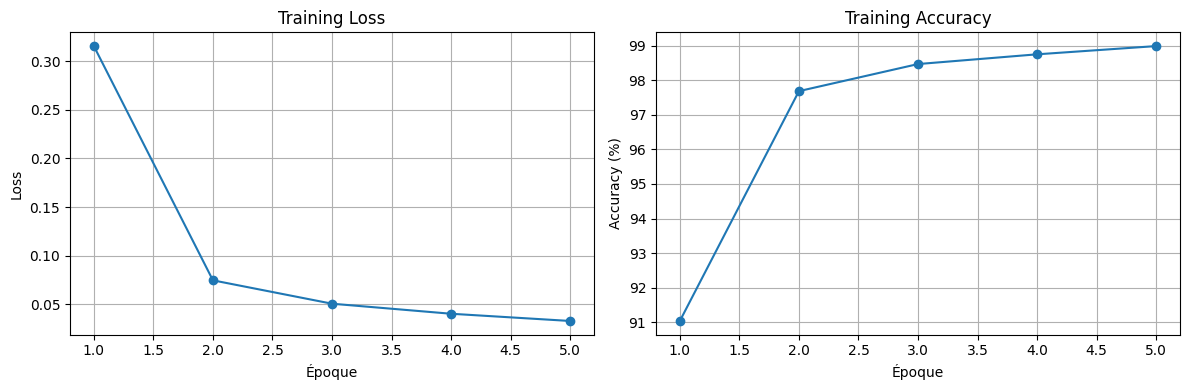

In [10]:

# Créer une figure avec deux graphiques
plt.figure(figsize=(12, 4))

# Graphique 1 : évolution de la perte
plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs + 1), train_losses, marker="o")
plt.title("Training Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.grid(True)

# Graphique 2 : évolution de l'accuracy
plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs + 1), train_accuracies, marker="o")
plt.title("Training Accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy (%)")
plt.grid(True)

# Ajuster les espaces entre les graphiques
plt.tight_layout()
plt.show()


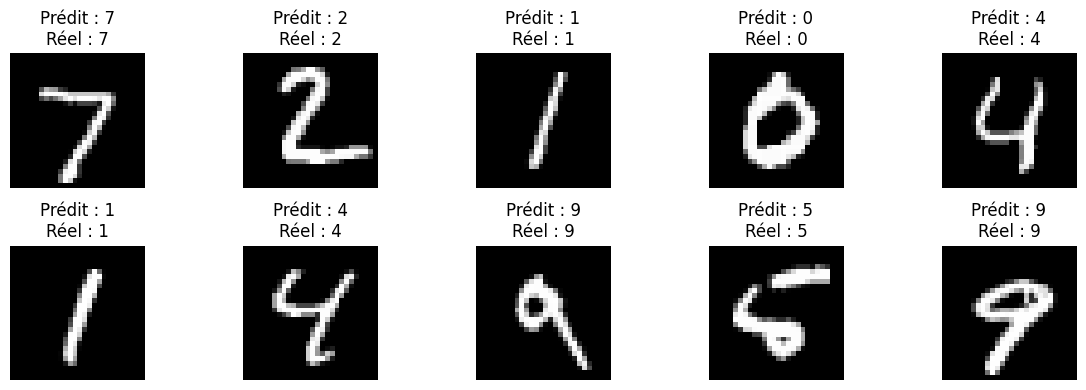

In [11]:

# Récupérer un batch de test
images, labels = next(iter(test_loader))

# Envoyer les images sur le même appareil que le modèle
images_device = images.to(device)

# Désactiver les gradients, car on ne fait que prédire
with torch.no_grad():
    outputs = model(images_device)

    # Choisir la classe ayant le score le plus élevé
    predictions = outputs.argmax(dim=1).cpu()

# Afficher les 10 premières images avec la prédiction et le vrai label
plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Afficher l'image
    plt.imshow(images[i].squeeze(), cmap="gray")

    # Afficher la prédiction et la vraie réponse
    plt.title(
        f"Prédit : {predictions[i].item()}\n"
        f"Réel : {labels[i].item()}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()
